<a href="https://colab.research.google.com/github/juju649/The-Coders-Solar-Shield-ibmz/blob/main/solarDataPreparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import gridstatus
import requests
import matplotlib.pyplot as plt
from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)

print("Imports successful — ready to download data.")

Imports successful — ready to download data.


In [7]:
# Download yesterday’s ERCOT data
ercot = gridstatus.Ercot()

yesterday = (
    pd.Timestamp.now(tz="America/Chicago").normalize()
    - pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

print("Requesting:", yesterday)

fuel_mix = ercot.get_fuel_mix(date=yesterday)

fuel_mix.to_csv(
    f"data/raw/ercot_fuel_mix_{yesterday}.csv",
    index=False
)

print("Rows:", len(fuel_mix))
print("Columns:", fuel_mix.columns.tolist())
display(fuel_mix.head())

2026-10-17 16:43:47 - INFO - Requesting https://www.ercot.com/api/1/services/read/dashboards/fuel-mix.json with {}
INFO:gridstatus:Requesting https://www.ercot.com/api/1/services/read/dashboards/fuel-mix.json with {}


Requesting: 2026-10-16
Rows: 288
Columns: ['Time', 'Coal and Lignite', 'Hydro', 'Nuclear', 'Power Storage', 'Solar', 'Wind', 'Natural Gas', 'Other']


,Time,Coal and Lignite,Hydro,Nuclear,Power Storage,Solar,Wind,Natural Gas,Other
0,2026-10-16 00:00:00-05:00,6054.729980,0.0,4894.039551,-47.291252,0.921833,23143.576172,21441.008972,50.200001
1,2026-10-16 00:05:00-05:00,6008.508789,0.0,4896.676270,391.024750,0.916961,23055.669922,21109.501114,50.299999
2,2026-10-16 00:10:00-05:00,6000.852051,0.0,4893.452148,431.239227,1.280471,23035.003906,20887.044121,50.200001
3,2026-10-16 00:15:00-05:00,5919.521484,0.0,4894.749512,403.414886,1.005960,23138.046875,20571.647606,50.099998
4,2026-10-16 00:20:00-05:00,5890.520508,0.0,4895.667969,674.221741,1.784204,23127.898438,20220.977005,50.299999


In [8]:
#Extract the solar column and convert timestamps
solar = fuel_mix[["Time", "Solar"]].copy()

solar = solar.rename(columns={
    "Time": "time_utc",
    "Solar": "solar_mw"
})

solar["time_utc"] = pd.to_datetime(solar["time_utc"], utc=True)
solar["solar_mw"] = pd.to_numeric(solar["solar_mw"], errors="coerce")

solar = solar.sort_values("time_utc").reset_index(drop=True)

display(solar.head())


,time_utc,solar_mw
0,2026-10-16 05:00:00+00:00,0.921833
1,2026-10-16 05:05:00+00:00,0.916961
2,2026-10-16 05:10:00+00:00,1.280471
3,2026-10-16 05:15:00+00:00,1.005960
4,2026-10-16 05:20:00+00:00,1.784204


In [6]:
#Check the data before changing anything
print("First timestamp:", solar["time_utc"].min())
print("Last timestamp:", solar["time_utc"].max())
print("Rows:", len(solar))

print("\nMissing values:")
print(solar.isna().sum())

print("\nDuplicate timestamps:")
print(solar["time_utc"].duplicated().sum())

print("\nMost common time intervals:")
print(solar["time_utc"].diff().value_counts().head())

print("\nSolar output summary:")
print(solar["solar_mw"].describe())

First timestamp: 2026-10-16 05:00:00+00:00
Last timestamp: 2026-10-17 04:55:00+00:00
Rows: 288

Missing values:
time_utc    0
solar_mw    0
dtype: int64

Duplicate timestamps:
0

Most common time intervals:
time_utc
0 days 00:05:00    287
Name: count, dtype: int64

Solar output summary:
count      288.000000
mean      5570.344169
std       7192.783104
min          0.141104
25%          1.162191
50%          2.141153
75%      13002.942871
max      19160.951172
Name: solar_mw, dtype: float64


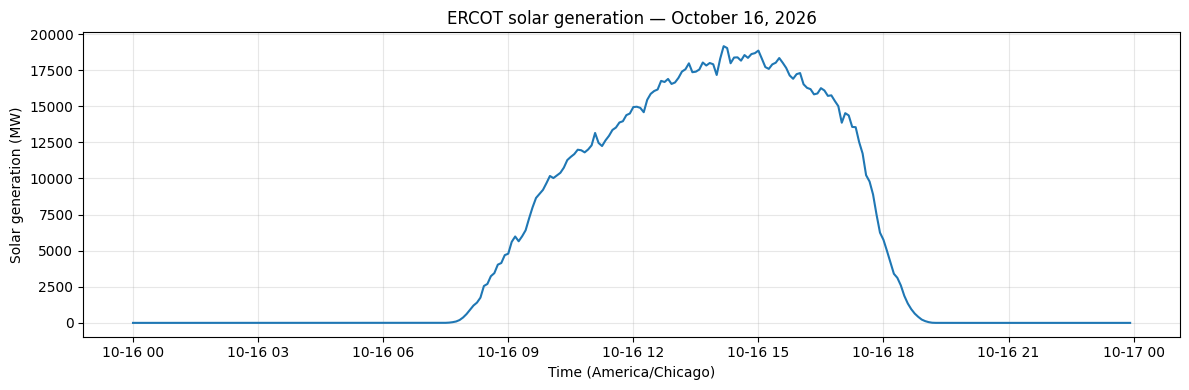

Saved solar_sample.csv and solar_sample_plot.png


In [9]:
#7. Plot the solar readings
import matplotlib.pyplot as plt

# Show Texas local time on the chart
local_time = solar["time_utc"].dt.tz_convert("America/Chicago")

plt.figure(figsize=(12, 4))
plt.plot(local_time, solar["solar_mw"])
plt.xlabel("Time (America/Chicago)")
plt.ylabel("Solar generation (MW)")
plt.title("ERCOT solar generation — October 16, 2026")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("data/processed/solar_sample_plot.png", dpi=150)
plt.show()

solar.to_csv("data/processed/solar_sample.csv", index=False)
print("Saved solar_sample.csv and solar_sample_plot.png")

In [10]:
from google.colab import files
files.download("data/processed/solar_sample.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
!pip -q install openpyxl

In [12]:
#Download the workbook:
import requests
from pathlib import Path

url = "https://www.ercot.com/files/docs/2026/02/09/IntGenbyFuel2026.xlsx"
excel_path = Path("data/raw/IntGenbyFuel2026.xlsx")
excel_path.parent.mkdir(parents=True, exist_ok=True)

response = requests.get(url, timeout=60)
response.raise_for_status()

# An XLSX workbook is a ZIP-format file.
if not response.content.startswith(b"PK"):
    raise ValueError("The response is not an XLSX file. Do not continue.")

excel_path.write_bytes(response.content)

print("Downloaded:", excel_path)
print("File size:", len(response.content), "bytes")

Downloaded: data/raw/IntGenbyFuel2026.xlsx
File size: 2296298 bytes


In [13]:
#Inspect the sheet names and first rows:
import pandas as pd

xl = pd.ExcelFile(excel_path)

print("Sheet names:")
print(xl.sheet_names)

# Read without assuming which row contains the headers.
for sheet in xl.sheet_names[:2]:
    print("\nSHEET:", sheet)
    preview = xl.parse(sheet, header=None, nrows=12)
    display(preview.iloc[:, :10])

Sheet names:
['Disclaimer', 'Summary', 'data_Summary_1', 'data_Summary_2', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

SHEET: Disclaimer


,0
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,Interval Generation by Fuel Report
8,For Planning Purposes Only
9,NaN



SHEET: Summary


,0,1,2,3,4,5,6,7,8,9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,"Energy, GWh",Jan*,Feb*,Mar*,Apr*,May*,Jun*,Jul*,Aug,Sep
8,Biomass,55.105695,44.195392,34.749288,9.744903,49.673011,49.837899,49.786877,52.456574,50.371904
9,Coal,5450.097428,4410.159486,3988.452082,4422.734718,4249.986448,5343.173032,6724.578628,6697.350686,6324.912502


In [14]:
# Show complete text without truncation
with pd.option_context("display.max_colwidth", None):
    print("DISCLAIMER")
    disclaimer = xl.parse("Disclaimer", header=None)
    for value in disclaimer.to_numpy().ravel():
        if pd.notna(value):
            print(value)

    print("\nAPRIL — FIRST 12 ROWS, FIRST 10 COLUMNS")
    april_preview = xl.parse("Apr", header=None, nrows=12)
    display(april_preview.iloc[:, :10])

    print("\nAPRIL — LAST 5 COLUMN HEADINGS")
    april = xl.parse("Apr")
    print(april.columns.tolist()[-5:])

DISCLAIMER
Interval Generation by Fuel Report
For Planning Purposes Only
This ERCOT Working Paper has been prepared for specific ERCOT and market participant purposes and has been  
developed from data provided through the settlement process.  The data may contain errors or become obsolete 
and thereby affect the conclusions and opinions of the Working Paper.  ERCOT MAKES NO WARRANTY, EXPRESS
OR IMPLIED,INCLUDING ANY WARRANTY OF MERCHANTABILITY OR FITNESS FOR ANY PARTICULAR PURPOSE, 
AND DISCLAIMS ANY AND ALL LIABILITY WITH RESPECT TO THE ACCURACY OF SAME OR THE FITNESS OR 
APPROPRIATENESS OF SAME FOR ANY PARTICULAR USE.  THIS ERCOT WORKING PAPER IS SUPPLIED WITH  
ALL FAULTS.
ERCOT publishes the values in this report based on the Initial Settlement occurring approximately five days after 
the Operating Day. These values are updated to reflect Final Settlements (occurring 55 days after each Operating
Day of the month), lagged by two months after the end of the month. On each tab of thi

,0,1,2,3,4,5,6,7,8,9
0,Date,Fuel,Settlement Type,Total,0:15,0:30,0:45,1:00,1:15,1:30
1,2026-04-01 00:00:00,Biomass,FINAL,358.922212,3.924274,3.920694,3.921005,3.916459,3.931264,3.927976
2,2026-04-01 00:00:00,Coal,FINAL,166006.836143,1822.892904,1855.724953,1872.923598,1860.842609,1842.369107,1866.601422
3,2026-04-01 00:00:00,Gas,FINAL,97106.767264,1016.239537,979.994384,929.066125,909.079515,872.749422,840.084921
4,2026-04-01 00:00:00,Gas-CC,FINAL,285692.315102,3370.320337,3207.08901,3136.833857,3112.008123,3091.397892,3100.84203
5,2026-04-01 00:00:00,Hydro,FINAL,839.309568,1.267844,1.262625,1.262902,1.273337,3.368273,6.268924
6,2026-04-01 00:00:00,Nuclear,FINAL,89396.948976,932.296907,932.154747,932.236918,932.062829,932.392371,932.446193
7,2026-04-01 00:00:00,Other,FINAL,24727.889806,99.552639,96.355209,77.446859,12.993074,27.823444,55.220772
8,2026-04-01 00:00:00,Solar,FINAL,183030.998104,0.000504,0.000494,0.000521,0.000494,0.000478,0.000468
9,2026-04-01 00:00:00,WSL,FINAL,-31025.976301,-57.644428,-69.162384,-65.522013,-130.174409,-223.934632,-204.167467



APRIL — LAST 5 COLUMN HEADINGS
['23:00', '23:15', '23:30', '23:45', '0:00']


In [15]:
#extracts April–September and checks the units against the workbook’s monthly GWh summary before converting anything.
import re
import numpy as np
import pandas as pd

months = ["Apr", "May", "Jun", "Jul", "Aug", "Sep"]
frames = []
monthly_checks = []

# Locate the summary header and Solar row
summary = xl.parse("Summary", header=None)

header_rows = summary.index[
    summary.iloc[:, 0].astype(str).str.contains(
        "Energy, GWh", regex=False
    )
]
solar_rows = summary.index[
    summary.iloc[:, 0].astype(str).str.strip().str.lower().eq("solar")
]

assert len(header_rows) == 1, "Could not identify the GWh header."
assert len(solar_rows) == 1, "Could not identify the summary Solar row."

header_row = header_rows[0]
solar_row = solar_rows[0]

for month in months:
    table = xl.parse(month)
    table.columns = [str(c).strip() for c in table.columns]

    solar_rows_month = table.loc[
        table["Fuel"].astype(str).str.strip().str.lower().eq("solar")
    ].copy()

    assert not solar_rows_month.empty, f"No Solar rows in {month}"

    time_cols = [
        c for c in table.columns
        if re.fullmatch(r"\d{1,2}:\d{2}", c)
    ]
    assert len(time_cols) == 96, (
        f"{month}: expected 96 interval columns, got {len(time_cols)}"
    )

    readings = solar_rows_month[time_cols].apply(
        pd.to_numeric, errors="raise"
    )

    # Verify interval values add up to the daily Total.
    daily_totals = pd.to_numeric(
        solar_rows_month["Total"], errors="raise"
    )
    assert np.allclose(
        readings.sum(axis=1),
        daily_totals,
        rtol=1e-6,
        atol=0.01
    ), f"{month}: interval sums do not match daily totals"

    # Find this month's GWh value in Summary.
    summary_columns = [
        c for c in summary.columns
        if str(summary.loc[header_row, c]).strip().rstrip("*") == month
    ]
    assert len(summary_columns) == 1, f"Summary column missing: {month}"

    summary_gwh = float(summary.loc[solar_row, summary_columns[0]])
    interval_sum = readings.sum().sum()

    monthly_checks.append({
        "month": month,
        "interval_sum_divided_by_1000": interval_sum / 1000,
        "summary_gwh": summary_gwh,
        "matches": np.isclose(
            interval_sum / 1000, summary_gwh,
            rtol=1e-6, atol=0.01
        )
    })

    long = solar_rows_month.melt(
        id_vars=["Date", "Settlement Type"],
        value_vars=time_cols,
        var_name="interval_end",
        value_name="solar_energy_raw"
    )

    # Convert time headings to minutes after the operating-day start.
    parts = long["interval_end"].str.split(":", expand=True)
    minutes = parts[0].astype(int) * 60 + parts[1].astype(int)

    # The last 0:00 interval ends at midnight on the following day.
    minutes = minutes.mask(minutes.eq(0), 1440)

    end_local = (
        pd.to_datetime(long["Date"]).dt.normalize()
        + pd.to_timedelta(minutes, unit="m")
    )

    long["time_utc"] = (
        end_local.dt.tz_localize("America/Chicago")
        .dt.tz_convert("UTC")
    )

    long["solar_energy_raw"] = pd.to_numeric(
        long["solar_energy_raw"], errors="raise"
    )

    frames.append(long)

checks = pd.DataFrame(monthly_checks)
display(checks)

assert checks["matches"].all(), (
    "Unit check failed. Stop here and share the output."
)

print("Monthly sums match GWh after dividing by 1,000.")
print("This supports interpreting interval values as MWh.")

history = pd.concat(frames, ignore_index=True)
history = history.sort_values("time_utc").reset_index(drop=True)

assert not history["time_utc"].duplicated().any(), (
    "Duplicate timestamps found. Investigate before continuing."
)

# Average MW = MWh / 0.25 hours
history["solar_mw"] = history["solar_energy_raw"] * 4

solar_history = history[["time_utc", "solar_mw"]].copy()

# Save separately from your five-minute sample.
history.to_csv(
    "data/processed/solar_history_with_settlement.csv", index=False
)
solar_history.to_csv(
    "data/processed/solar_15min.csv", index=False
)

print("\nRows:", len(solar_history))
print("First timestamp:", solar_history["time_utc"].min())
print("Last timestamp:", solar_history["time_utc"].max())
print("\nMissing values:")
print(solar_history.isna().sum())
print("\nTime intervals:")
print(solar_history["time_utc"].diff().value_counts())
print("\nMaximum average solar MW:", solar_history["solar_mw"].max())

,month,interval_sum_divided_by_1000,summary_gwh,matches
0,Apr,5771.080699,5771.080699,True
1,May,7884.710406,7884.710406,True
2,Jun,8015.980656,8015.980656,True
3,Jul,9658.420030,9658.420030,True
4,Aug,10044.098203,10044.098203,True
5,Sep,8056.110043,8056.110043,True


Monthly sums match GWh after dividing by 1,000.
This supports interpreting interval values as MWh.

Rows: 17568
First timestamp: 2026-04-01 05:15:00+00:00
Last timestamp: 2026-10-01 05:00:00+00:00

Missing values:
time_utc    0
solar_mw    0
dtype: int64

Time intervals:
time_utc
0 days 00:15:00    17567
Name: count, dtype: int64

Maximum average solar MW: 35342.585092


In [16]:
#download hourly weather for the five locations
import requests
import pandas as pd
from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)

locations = {
    "far_west": (31.0, -102.5),
    "west": (31.9, -102.1),
    "northwest": (33.6, -101.9),
    "north_central": (32.0, -96.5),
    "south": (29.4, -98.5),
}

variables = [
    "cloud_cover",
    "shortwave_radiation",
    "temperature_2m",
]

weather_frames = []

for name, (lat, lon) in locations.items():
    print("Downloading:", name)

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": lat,
            "longitude": lon,
            "start_date": "2026-04-01",
            "end_date": "2026-10-01",
            "hourly": ",".join(variables),
            "timezone": "UTC",
            "temperature_unit": "celsius",
        },
        timeout=120,
    )

    response.raise_for_status()
    payload = response.json()

    if "hourly" not in payload:
        raise ValueError(f"{name}: unexpected response: {payload}")

    # Preserve the original response, including units and coordinates.
    Path(f"data/raw/weather_{name}.json").write_text(
        response.text, encoding="utf-8"
    )

    weather = pd.DataFrame(payload["hourly"])
    weather = weather.rename(columns={"time": "time_utc"})
    weather["time_utc"] = pd.to_datetime(
        weather["time_utc"], utc=True
    )

    for column in variables:
        weather[column] = pd.to_numeric(
            weather[column], errors="raise"
        )

    assert not weather["time_utc"].duplicated().any(), (
        f"Duplicate timestamps for {name}"
    )

    weather["location"] = name
    weather.to_csv(f"data/raw/weather_{name}.csv", index=False)
    weather_frames.append(weather)

    print("Rows:", len(weather))
    print("Units:", payload.get("hourly_units"))

weather_all = pd.concat(weather_frames, ignore_index=True)

grouped = weather_all.groupby("time_utc")
counts = grouped[variables].count()
location_counts = grouped["location"].nunique()

# Require five nonmissing values for every weather variable.
complete = counts.eq(5).all(axis=1) & location_counts.eq(5)

weather_hourly = grouped[variables].mean()
weather_hourly.loc[~complete, variables] = float("nan")
weather_hourly = weather_hourly.sort_index()

weather_hourly.to_csv("data/processed/weather_hourly_average.csv")

print("\nLocations downloaded:", weather_all["location"].nunique())
print("Hourly timestamps:", len(weather_hourly))
print("Hours with incomplete weather:", int((~complete).sum()))
print("\nMissing values:")
print(weather_hourly.isna().sum())

display(weather_hourly.head())

Downloading: far_west
Rows: 4416
Units: {'time': 'iso8601', 'cloud_cover': '%', 'shortwave_radiation': 'W/m²', 'temperature_2m': '°C'}
Downloading: west
Rows: 4416
Units: {'time': 'iso8601', 'cloud_cover': '%', 'shortwave_radiation': 'W/m²', 'temperature_2m': '°C'}
Downloading: northwest
Rows: 4416
Units: {'time': 'iso8601', 'cloud_cover': '%', 'shortwave_radiation': 'W/m²', 'temperature_2m': '°C'}
Downloading: north_central
Rows: 4416
Units: {'time': 'iso8601', 'cloud_cover': '%', 'shortwave_radiation': 'W/m²', 'temperature_2m': '°C'}
Downloading: south
Rows: 4416
Units: {'time': 'iso8601', 'cloud_cover': '%', 'shortwave_radiation': 'W/m²', 'temperature_2m': '°C'}

Locations downloaded: 5
Hourly timestamps: 4416
Hours with incomplete weather: 0

Missing values:
cloud_cover            0
shortwave_radiation    0
temperature_2m         0
dtype: int64


,cloud_cover,shortwave_radiation,temperature_2m
time_utc,,,
2026-04-01 00:00:00+00:00,65.8,209.6,30.08
2026-04-01 01:00:00+00:00,46.8,51.4,28.18
2026-04-01 02:00:00+00:00,94.0,0.0,26.70
2026-04-01 03:00:00+00:00,87.2,0.0,25.30
2026-04-01 04:00:00+00:00,70.8,0.0,23.96


In [17]:
# 1. Put solar data on a complete 15-minute grid.
solar_grid = (
    solar_history
    .set_index("time_utc")[["solar_mw"]]
    .sort_index()
    .asfreq("15min")
)

# 2. Match each solar timestamp to the latest hourly weather.
# The 59-minute limit prevents carrying weather across long gaps.
weather_aligned = weather_hourly.reindex(
    solar_grid.index,
    method="ffill",
    tolerance=pd.Timedelta(minutes=59)
)

features = solar_grid.join(weather_aligned)

# 3. Create past-looking inputs BEFORE removing any rows.
features["solar_lag15"] = features["solar_mw"].shift(1)
features["solar_lag30"] = features["solar_mw"].shift(2)
features["solar_lag60"] = features["solar_mw"].shift(4)

features["change_15"] = (
    features["solar_mw"] - features["solar_lag15"]
)

local_time = features.index.tz_convert("America/Chicago")
features["hour_local"] = local_time.hour
features["day_of_year"] = local_time.dayofyear

# 4. Calculate the daylight proxy from proposed training data only.
# Include the final interval of July, ending August 1 at midnight.
training_end = pd.Timestamp(
    "2026-08-01 00:00:00",
    tz="America/Chicago"
).tz_convert("UTC")

training_solar = features.loc[
    features.index <= training_end, "solar_mw"
]

daylight_threshold = 0.05 * training_solar.max()

features["is_daylight"] = (
    features["solar_mw"] > daylight_threshold
).astype(int)

# 5. Create the future answer, never to be used as a model input.
features["target_solar_15"] = features["solar_mw"].shift(-1)

# Drop unavailable lags and targets before assigning the drop label.
rows_before = len(features)
features = features.dropna().copy()

features["target_drop"] = (
    features["target_solar_15"] < 0.8 * features["solar_mw"]
).astype(int)

# 6. Arrange columns exactly as agreed.
column_order = [
    "solar_mw",
    "solar_lag15",
    "solar_lag30",
    "solar_lag60",
    "change_15",
    "hour_local",
    "day_of_year",
    "cloud_cover",
    "shortwave_radiation",
    "temperature_2m",
    "is_daylight",
    "target_solar_15",
    "target_drop",
]

features = features[column_order]
features.index.name = "time_utc"

# 7. Save with explicit UTC timestamps.
export = features.reset_index()
export["time_utc"] = export["time_utc"].dt.strftime(
    "%Y-%m-%dT%H:%M:%SZ"
)
export.to_csv("data/processed/features.csv", index=False)

# Save how the daylight flag was calculated.
Path("data/processed/daylight_threshold.txt").write_text(
    "Proposed training period: April-July 2026\n"
    f"Training interval-end cutoff UTC: {training_end}\n"
    f"Daylight threshold MW: {daylight_threshold}\n"
    "Definition: solar_mw > 5% of training-period maximum\n",
    encoding="utf-8"
)

# 8. Report checks.
daytime = features.loc[features["is_daylight"].eq(1)]

print("Rows saved:", len(features))
print("Rows removed:", rows_before - len(features))
print("Total missing values:", features.isna().sum().sum())
print("Daylight threshold MW:", daylight_threshold)
print("Daytime rows:", len(daytime))
print("Daytime drops:", int(daytime["target_drop"].sum()))

print("\nDaytime drop labels:")
print(daytime["target_drop"].value_counts().sort_index())

display(export.head())

Rows saved: 17563
Rows removed: 5
Total missing values: 0
Daylight threshold MW: 1767.1292546000002
Daytime rows: 9072
Daytime drops: 861

Daytime drop labels:
target_drop
0    8211
1     861
Name: count, dtype: int64


,time_utc,solar_mw,solar_lag15,solar_lag30,solar_lag60,change_15,hour_local,day_of_year,cloud_cover,shortwave_radiation,temperature_2m,is_daylight,target_solar_15,target_drop
0,2026-04-01T06:15:00Z,0.001912,0.001976,0.002084,0.002016,-0.000064,1,91,58.4,0.0,21.84,0,0.001872,0
1,2026-04-01T06:30:00Z,0.001872,0.001912,0.001976,0.001976,-0.000040,1,91,58.4,0.0,21.84,0,0.001936,0
2,2026-04-01T06:45:00Z,0.001936,0.001872,0.001912,0.002084,0.000064,1,91,58.4,0.0,21.84,0,0.001880,0
3,2026-04-01T07:00:00Z,0.001880,0.001936,0.001872,0.001976,-0.000056,2,91,50.0,0.0,21.14,0,0.001976,0
4,2026-04-01T07:15:00Z,0.001976,0.001880,0.001936,0.001912,0.000096,2,91,50.0,0.0,21.14,0,0.001904,0


In [19]:
from google.colab import files

files.download("data/processed/features.csv")
files.download("data/processed/daylight_threshold.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
drop_by_hour = (
    features.loc[features["is_daylight"].eq(1)]
    .groupby("hour_local")["target_drop"]
    .agg(daytime_rows="count", drop_rows="sum")
)

drop_by_hour["drop_rate_percent"] = (
    100 * drop_by_hour["drop_rows"] / drop_by_hour["daytime_rows"]
).round(2)

display(drop_by_hour)

,daytime_rows,drop_rows,drop_rate_percent
hour_local,,,
7,251,0,0.00
8,715,0,0.00
9,731,0,0.00
10,732,0,0.00
11,732,0,0.00
12,732,0,0.00
13,732,0,0.00
14,732,0,0.00
15,732,0,0.00


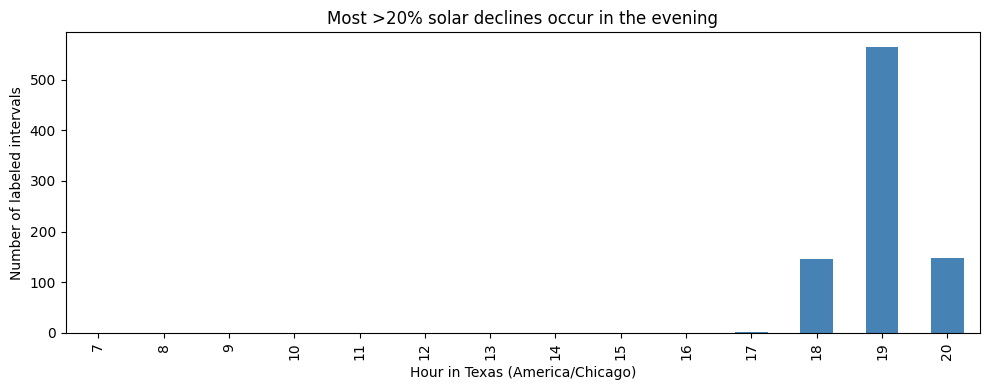

In [21]:
import matplotlib.pyplot as plt

ax = drop_by_hour["drop_rows"].plot(
    kind="bar",
    figsize=(10, 4),
    color="steelblue"
)

ax.set_xlabel("Hour in Texas (America/Chicago)")
ax.set_ylabel("Number of labeled intervals")
ax.set_title("Most >20% solar declines occur in the evening")

plt.tight_layout()
plt.savefig(
    "data/processed/drop_labels_by_hour.png",
    dpi=150
)
plt.show()